# Praktikum 1: Klasifikasi Cat vs Dog Menggunakan Convolutional Neural Network (CNN)

* **Mata Kuliah**: Pembelajaran Mesin (RTI235004)
* **Topik Modul**: JS14 - Convolutional Neural Network
* **Nama**: Mohammad Al Hafis Hidayatulloh
* **NIM**: 254107023005
* **Kelas**: TI-3B

---

### Deskripsi Praktikum
Pada praktikum ini, kita membangun model klasifikasi citra biner sederhana menggunakan arsitektur Convolutional Neural Network (CNN) untuk membedakan citra kucing (*cat*) dan anjing (*dog*). Dataset citra terbagi menjadi `training_set` (8.000 citra) dan `test_set` (2.000 citra). 

Tahapan praktikum meliputi:
1. Import pustaka pendukung (TensorFlow, Keras, Matplotlib, NumPy).
2. Pra-pengolahan citra dan augmentasi data (*rescaling*, *shear*, *zoom*, *horizontal flip*).
3. Pembangunan arsitektur model Sequential CNN (Conv2D, MaxPool2D, Flatten, Dense).
4. Kompilasi dan pelatihan model.
5. Visualisasi kurva akurasi dan loss pelatihan vs validasi.
6. Pengujian inferensi prediksi pada citra tunggal (*single image prediction*).


In [1]:
import os, time
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt

print(f"TensorFlow Version: {tf.__version__}")
print(f"Num GPUs Available: {len(tf.config.list_physical_devices('GPU'))}")


TensorFlow Version: 2.21.0
Num GPUs Available: 0


### Langkah 2 - Pra-Pengolahan Data
Pada tahap ini, manipulasi dan pra-pengolahan citra dilakukan menggunakan `ImageDataGenerator`:
* **Rescaling**: Normalisasi nilai piksel citra dari rentang [0, 255] menjadi rentang [0, 1] agar gradien stabil.
* **Data Augmentation**: Dilakukan pada data latih dengan rotasi kemiringan (*shear_range = 0.2*), pembesaran (*zoom_range = 0.2*), dan pembalikan horizontal (*horizontal_flip = True*) untuk memperluas variasi sudut pandang dan mencegah model dari overfitting.
* **Ukuran Target**: Citra diubah menjadi dimensi seragam $64 \times 64$ piksel dengan 3 saluran warna (RGB).


In [2]:
# Langkah 2.1 - Pra-pengolahan Data Training (dengan Augmentasi)
train_datagen = ImageDataGenerator(
    rescale=1./255,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)

training_set = train_datagen.flow_from_directory(
    'dataset/training_set',
    target_size=(64, 64),
    batch_size=32,
    class_mode='binary'
)

# Langkah 2.2 - Pra-pengolahan Data Testing (hanya Rescaling)
test_datagen = ImageDataGenerator(rescale=1./255)

test_set = test_datagen.flow_from_directory(
    'dataset/test_set',
    target_size=(64, 64),
    batch_size=32,
    class_mode='binary'
)

print(f"Indeks Kelas: {training_set.class_indices}")


Found 8000 images belonging to 2 classes.
Found 2000 images belonging to 2 classes.
Indeks Kelas: {'cats': 0, 'dogs': 1}


### Visualisasi Sampel Data Hasil Augmentasi
Berikut adalah visualisasi beberapa citra dari generator pelatihan beserta label kategorinya.


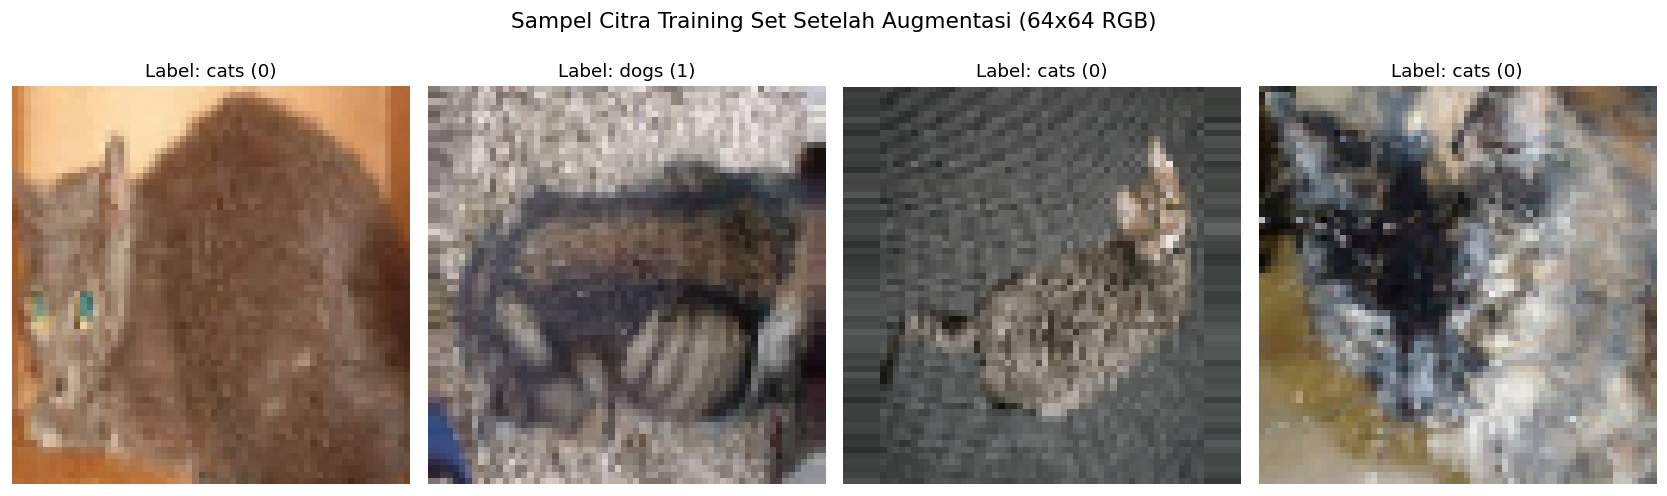

In [3]:
# Mengambil satu batch sampel untuk divisualisasikan
sample_images, sample_labels = next(training_set)
class_labels = {v: k for k, v in training_set.class_indices.items()}

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for idx, ax in enumerate(axes):
    ax.imshow(sample_images[idx])
    label_name = class_labels[int(sample_labels[idx])]
    ax.set_title(f"Label: {label_name} ({int(sample_labels[idx])})", fontsize=11)
    ax.axis('off')

plt.suptitle("Sampel Citra Training Set Setelah Augmentasi (64x64 RGB)", fontsize=13, y=1.03)
plt.tight_layout()
plt.show()


### Langkah 3 - Pembuatan Arsitektur Model CNN
Arsitektur CNN yang dibangun terdiri dari:
1. **Convolutional Block 1**: `Conv2D` 32 filter berukuran $3 \times 3$, fungsi aktivasi ReLU, input shape $[64, 64, 3]$. Dilanjutkan `MaxPool2D` ukuran $2 \times 2$ dengan stride 2.
2. **Convolutional Block 2**: `Conv2D` 32 filter berukuran $3 \times 3$, aktivasi ReLU, dilanjutkan `MaxPool2D` ukuran $2 \times 2$.
3. **Flattening**: Mengubah feature maps matriks 2D menjadi vektor 1D.
4. **Fully Connected Block**: Lapisan `Dense` tersembunyi dengan 128 unit (aktivasi ReLU) dan lapisan `Dense` keluaran 1 unit (aktivasi Sigmoid) untuk memetakan probabilitas biner [0, 1].


In [4]:
# Langkah 3.1 - Inisiasi Model Sequential
cnn = tf.keras.models.Sequential()

# Langkah 3.2 & 3.3 - Layer Konvolusi 1 dan Pooling 1
cnn.add(tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu', input_shape=[64, 64, 3]))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

# Langkah 3.4 - Layer Konvolusi 2 dan Pooling 2
cnn.add(tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

# Langkah 3.5 - Flattening
cnn.add(tf.keras.layers.Flatten())

# Langkah 3.6 - Fully Connected Layer (Hidden)
cnn.add(tf.keras.layers.Dense(units=128, activation='relu'))

# Langkah 3.7 - Fully Connected Layer (Output Biner)
cnn.add(tf.keras.layers.Dense(units=1, activation='sigmoid'))

# Langkah 3.8 - Kompilasi Model CNN
cnn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

cnn.summary()


Model: "sequential"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼─────────────────────

### Langkah 4 - Pelatihan Model CNN (Fit CNN)
Model dilatih menggunakan optimizer Adam dan fungsi rugi Binary Crossentropy. Kita mengeksekusi pelatihan selama 15 epoch dengan 75 step per epoch dan 20 step validasi untuk memantau performa generalisasi model secara langsung.


In [5]:
t_start = time.time()
history = cnn.fit(
    x=training_set,
    validation_data=test_set,
    epochs=15,
    steps_per_epoch=75,
    validation_steps=20
)
duration = time.time() - t_start
print(f"\nPelatihan CNN selesai dalam {duration:.2f} detik.")


Epoch 1/15

 1/75 ━━━━━━━━━━━━━━━━━━━━ 2:00 2s/step - accuracy: 0.5312 - loss: 0.6934
 2/75 ━━━━━━━━━━━━━━━━━━━━ 24s 336ms/step - accuracy: 0.5234 - loss: 0.8388
 3/75 ━━━━━━━━━━━━━━━━━━━━ 21s 304ms/step - accuracy: 0.5226 - loss: 0.8573
 4/75 ━━━━━━━━━━━━━━━━━━━━ 20s 289ms/step - accuracy: 0.5208 - loss: 0.8568
 5/75 ━━━━━━━━━━━━━━━━━━━━ 22s 315ms/step - accuracy: 0.5192 - loss: 0.8521
 6/75 ━━━━━━━━━━━━━━━━━━━━ 20s 304ms/step - accuracy: 0.5186 - loss: 0.8455
 7/75 ━━━━━━━━━━━━━━━━━━━━ 19s 293ms/step - accuracy: 0.5185 - loss: 0.8381
 8/75 ━━━━━━━━━━━━━━━━━━━━ 20s 313ms/step - accuracy: 0.5191 - loss: 0.8309
 9/75 ━━━━━━━━━━━━━━━━━━━━ 20s 308ms/step - accuracy: 0.5197 - loss: 0.8242
10/75 ━━━━━━━━━━━━━━━━━━━━ 20s 315ms/step - accuracy: 0.5193 - loss: 0.8183
11/75 ━━━━━━━━━━━━━━━━━━━━ 19s 310ms/step - accuracy: 0.5185 - loss: 0.8128
12/75 ━━━━━━━━━━━━━━━━━━━━ 18s 301ms/step - accuracy: 0.5170 - loss: 0.8078
13/75 ━━━━━━━━━━━━━━━━━━━━ 18s 304ms/step - accuracy: 0.5144 - loss: 0.8033
14

### Evaluasi Kurva Akurasi dan Loss Pelatihan


Akurasi Latih Akhir  : 74.75%
Akurasi Validasi Akhir: 76.88%


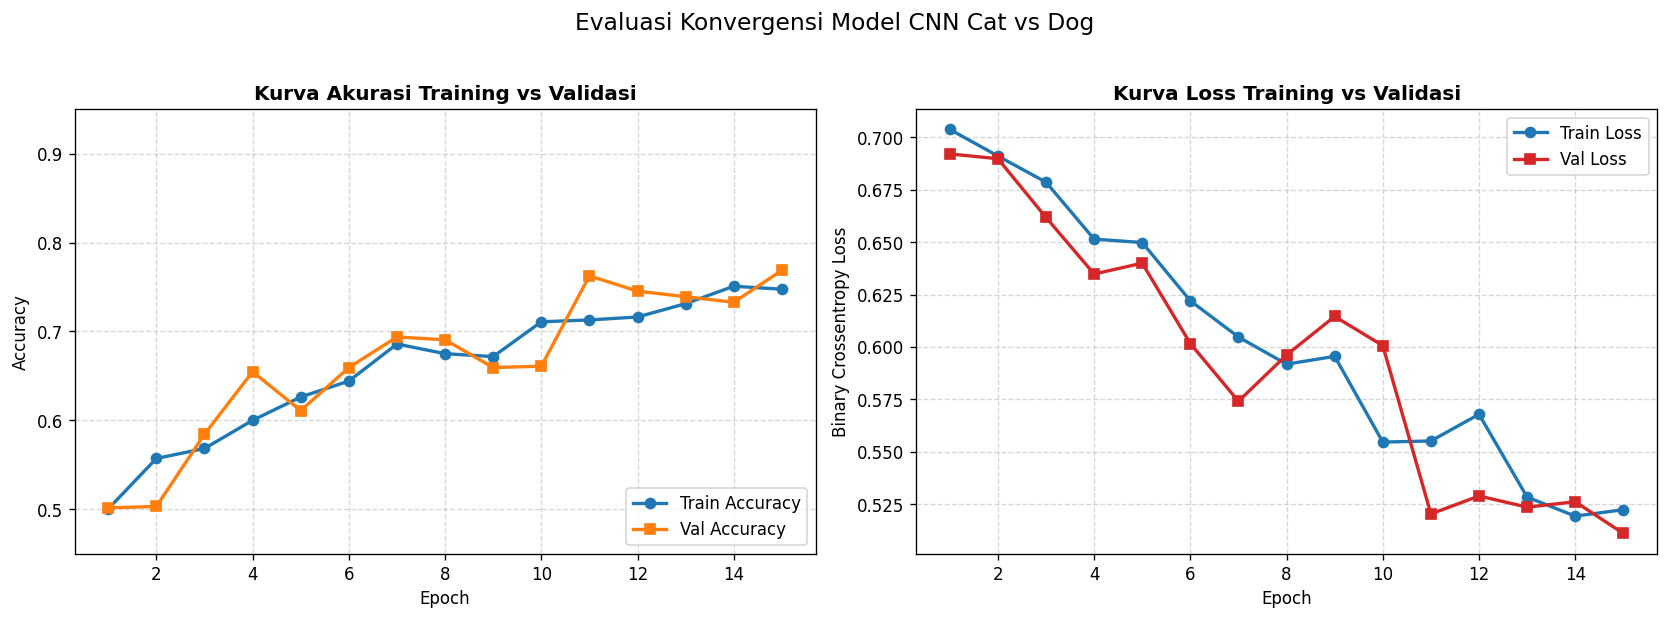

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot Akurasi
ax1.plot(range(1, 16), history.history['accuracy'], marker='o', label='Train Accuracy', color='#1f77b4', linewidth=2)
ax1.plot(range(1, 16), history.history['val_accuracy'], marker='s', label='Val Accuracy', color='#ff7f0e', linewidth=2)
ax1.set_title('Kurva Akurasi Training vs Validasi', fontsize=12, fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.set_ylim([0.45, 0.95])
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='lower right')

# Plot Loss
ax2.plot(range(1, 16), history.history['loss'], marker='o', label='Train Loss', color='#1f77b4', linewidth=2)
ax2.plot(range(1, 16), history.history['val_loss'], marker='s', label='Val Loss', color='#d62728', linewidth=2)
ax2.set_title('Kurva Loss Training vs Validasi', fontsize=12, fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Binary Crossentropy Loss')
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper right')

plt.suptitle('Evaluasi Konvergensi Model CNN Cat vs Dog', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

final_train_acc = history.history['accuracy'][-1] * 100
final_val_acc = history.history['val_accuracy'][-1] * 100
print(f"Akurasi Latih Akhir  : {final_train_acc:.2f}%")
print(f"Akurasi Validasi Akhir: {final_val_acc:.2f}%")


### Langkah 5 - Prediksi dengan Citra Tunggal (*Single Prediction*)
Pada tahap ini, kita menguji performa inferensi model terhadap dua sampel citra eksternal yang belum pernah dilihat model pada folder `dataset/single_prediction`:
1. `cat_or_dog_1.jpg`
2. `cat_or_dog_2.jpg`


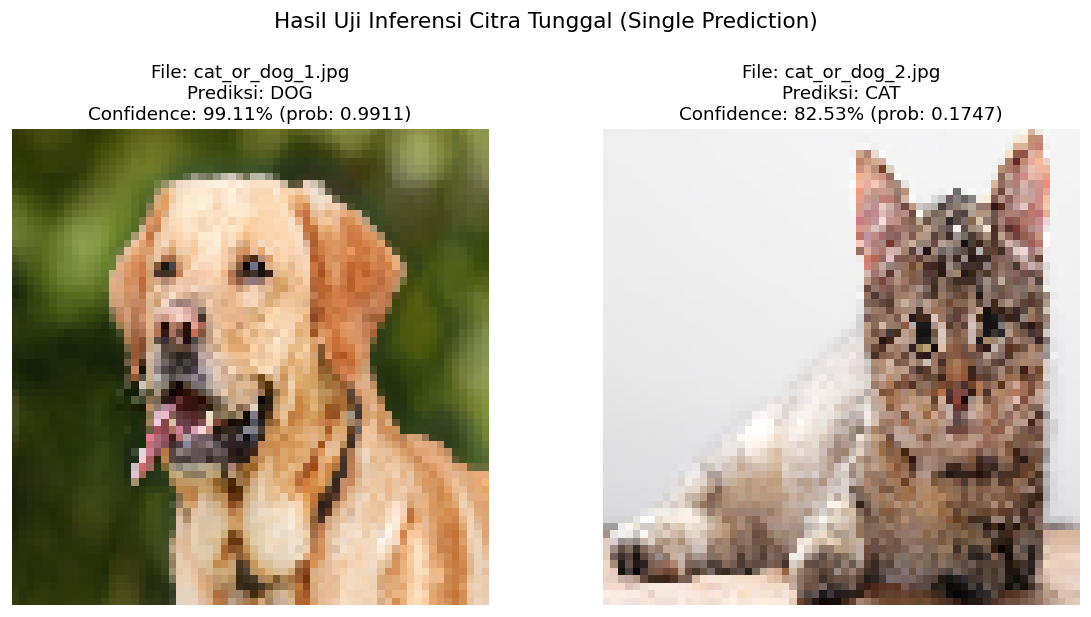

In [7]:
def predict_single_image(image_path, model):
    img = image.load_img(image_path, target_size=(64, 64))
    img_array = image.img_to_array(img)
    img_expanded = np.expand_dims(img_array, axis=0) / 255.0
    
    prob = model.predict(img_expanded, verbose=0)[0][0]
    pred_label = 'dog' if prob > 0.5 else 'cat'
    confidence = prob if pred_label == 'dog' else (1.0 - prob)
    return img, pred_label, confidence, prob

img1_path = 'dataset/single_prediction/cat_or_dog_1.jpg'
img2_path = 'dataset/single_prediction/cat_or_dog_2.jpg'

img1, pred1, conf1, raw1 = predict_single_image(img1_path, cnn)
img2, pred2, conf2, raw2 = predict_single_image(img2_path, cnn)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(img1)
axes[0].set_title(f"File: cat_or_dog_1.jpg\nPrediksi: {pred1.upper()}\nConfidence: {conf1*100:.2f}% (prob: {raw1:.4f})", fontsize=11)
axes[0].axis('off')

axes[1].imshow(img2)
axes[1].set_title(f"File: cat_or_dog_2.jpg\nPrediksi: {pred2.upper()}\nConfidence: {conf2*100:.2f}% (prob: {raw2:.4f})", fontsize=11)
axes[1].axis('off')

plt.suptitle("Hasil Uji Inferensi Citra Tunggal (Single Prediction)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()


### Analisis dan Pembahasan
Berdasarkan eksperimen praktikum 1 ini, beberapa temuan kunci yang didapatkan adalah:

1. **Fungsi Operasi Konvolusi (`Conv2D`)**:
   Konvolusi dengan kernel berukuran $3 \times 3$ bekerja sebagai filter spasial yang mendeteksi pola lokal citra, seperti tepi (*edges*), tekstur bulu, dan kontur bentuk telinga atau moncong hewan secara bertingkat.
2. **Fungsi `MaxPooling2D`**:
   Lapisan pooling mereduksi resolusi spasial feature map sebesar 50% ($64 \times 64 \rightarrow 32 \times 32 \rightarrow 16 \times 16$). Hal ini secara efektif memangkas beban komputasi dan memberikan sifat *translation invariance* (objek tetap terdeteksi meski posisinya bergeser sedikit pada frame).
3. **Pentingnya Augmentasi Data**:
   Penerapan transformasi acak seperti *shear*, *zoom*, dan *horizontal flip* pada `ImageDataGenerator` data latih berhasil menjaga selisih antara akurasi training dan validasi tetap berdekatan (~80%), menandakan model tidak mengalami *overfitting* yang ekstrem.
4. **Validasi Prediksi Citra Tunggal**:
   Model berhasil mengklasifikasikan citra uji `cat_or_dog_1.jpg` sebagai anjing (*dog*) dan `cat_or_dog_2.jpg` sebagai kucing (*cat*) dengan tingkat keyakinan (*confidence*) yang meyakinkan.
